# 10. Physics-Informed Neural Networks

# Steady 1D Advection–Diffusion Equation

We consider the **steady 1D advection–diffusion equation** with positive diffusion:

$$
u \frac{\partial \phi}{\partial x} + \nu \frac{\partial^2 \phi}{\partial x^2} = f(x)
$$

with **Dirichlet boundary conditions**:

$$
\phi(0) = \sin(0) = 0, \quad 
\phi(L) = \sin(w L)
$$

Here, we set 

$$
L = 4 \pi,
$$ 

so 

$$
\phi(L) = \sin(4 \pi w) = 0
$$ 

for integer multiples of $w$.

---

## Analytical Solution

Assume the analytical solution:

$$
\phi(x) = \sin(w x)
$$

---

## Forcing Term

The corresponding forcing term is:

$$
f(x) = u \, w \, \cos(w x) - \nu \, w^2 \, \sin(w x)
$$

---

## Parameters

| Symbol  | Description |
|---------|-------------|
| $u$     | Advection velocity |
| $\nu$   | Diffusion coefficient |
| $w$     | Wave number of the sinusoidal solution |
| $\phi$  | Scalar field (solution) |
| $f(x)$  | Forcing term |
| $L$     | Computational domain, $x \in [0, L]$ |

## Tutorial: Setting Variables and Running the Model

For each steady advection–diffusion problem, define the PDE coefficients as:

### Define the forcing term f(x)

Adjust the function:

    f_rhs_fun

---

### PDE Configuration

Create a configuration dictionary for the PDE parameters:

```python

    pde_config = {
        "u": 1.0,        # Advection velocity
        "nu": 1.0,       # Diffusion coefficient
        "f_tensor": f_rhs_t  # right hand side function
    }

```


### Boundary Conditions

Define the boundary condition configuration as:

```python

    bc_config = {"phi_bc_t": phi_bc_t}
```

where:

- `phi_bc_t` is a tensor (or vector) containing the Dirichlet boundary values  
  at the domain boundaries \( x = 0 \) and \( x = L \), respectively. 



In [1]:
import tensorflow as tf
from tensorflow import keras
from typing import List

# Device handling
device = "GPU:0" if tf.config.list_physical_devices('GPU') else "CPU:0"

class PINN(keras.Model):
    """Physics-Informed Neural Network (PINN) model.
    Parameters:
        layers (List[int]): List defining the number of neurons in each layer, including input and output layers.
    """
    def __init__(self, layers: List[int]) -> None:
        super().__init__()
        self.act = tf.nn.tanh
        
        # Build dense layers
        self.layers_list = []
        for i in range(len(layers) - 1):
            self.layers_list.append(
                keras.layers.Dense(layers[i + 1], 
                                     kernel_initializer='glorot_uniform',
                                     bias_initializer='zeros')
            )
    
    def call(self, x: tf.Tensor) -> tf.Tensor:
        y = x
        for i, layer in enumerate(self.layers_list[:-1]):
            y = self.act(layer(y))
        return self.layers_list[-1](y)
    

In [2]:
import numpy as np

def exact_solution_second_order_1d_general(
    x: np.ndarray,
    w: float,
) -> np.ndarray:
    """
    Exact solution for 1D second order PDE u * dphi/dx + nu * d²phi/dx² = u * w * cos(wx) - nu * (w^2) * sin(wx)

    Returns phi(x) = sin(wx).
    """

    exact_phi = np.sin(w * x)
    return exact_phi.astype(np.float64)

In [3]:
def pde_residual_1d_second_order(
    model: keras.Model,
    x_tensor: tf.Tensor,
    u: float = 1.0,
    nu: float = 1.0,
    f_tensor: tf.Tensor = None,  # vector of rhs
) -> tf.Tensor:
    """
    Compute PDE residual for steady 1D second order equation
    (advection-diffusion equation with Peclet = 1) with source f(x).

    1 * dphi/dx + 1 * d²phi/dx² = -sin(x) + cos(x)

    Parameters
    ----------
    model : keras.Model
        PINN model predicting c(x).
    x_tensor : tf.Tensor
        Collocation points, shape (N, 1).
    u : float
        Advection coefficient.
    nu : float
        Diffusion coefficient.
    f_tensor : tf.Tensor
        Source term f(x) at collocation points, shape (N, 1).

    Returns
    -------
    r : tf.Tensor
        Residual values at collocation points, shape (N, 1).
    """
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch(x_tensor)
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch(x_tensor)
            c_pred = model(x_tensor)

        c_x = tape1.gradient(c_pred, x_tensor)

    c_xx = tape2.gradient(c_x, x_tensor)

    u_t = tf.constant(u, dtype=x_tensor.dtype)
    nu_t = tf.constant(nu, dtype=x_tensor.dtype)

    if f_tensor is None:
        f_tensor = tf.zeros_like(x_tensor)

    # residual: u * c_x - nu * c_xx - f(x)
    r = u_t * c_x + nu_t * c_xx - f_tensor

    del tape1, tape2
    return r

In [4]:
def gen_testdata(
    n_test: int = 1000,
    length: float = 1,
) -> np.ndarray:
    x = np.linspace(0.0, length, n_test)[:, None]
    return x.astype(np.float64)

In [5]:
from typing import Tuple
from numpy.typing import NDArray

def bc_residual_Dirichlet_1D_v2(
    model: keras.Model, x_bc_t: tf.Tensor, phi_bc_t: tf.Tensor
) -> tf.Tensor:
    """
    NOTE: Output is vector of nodal boundary residuals unlike bc_residual_Dirichlet_1D
    output which is scalar

    Compute the Dirichlet boundary condition loss for a 1D problem.

    Parameters
    ----------
    model : keras.Model
        The neural network model.
    x_bc_t : tf.Tensor
        Tensor of boundary locations.
    phi_bc_t : tf.Tensor
        Tensor of Dirichlet boundary values.

    Returns
    -------
    tf.Tensor (1,) scalar
        Mean squared error loss between predicted and target boundary values.
    """
    phi_pred_b = model(x_bc_t)
    return phi_pred_b - phi_bc_t

def gen_bc_tf(
    x_bc: NDArray[np.float64],  # shape (N,) or (N,1)
    phi_bc: NDArray[np.float64],  # shape (N,) or (N,1)
    dtype: tf.dtypes.DType = tf.float32,
) -> Tuple[tf.Tensor, tf.Tensor]:
    """
    Convert boundary condition arrays (locations and values) into TensorFlow tensors.

    Parameters
    ----------
    x_bc : NDArray[np.float64]
        Boundary locations, shape (N,) or (N,1).
    phi_bc : NDArray[np.float64]
        Boundary values at these locations, shape (N,) or (N,1).
    dtype : tf.dtypes.DType
        TensorFlow dtype for tensors (default: tf.float32).

    Returns
    -------
    x_bc_t : tf.Tensor
        TensorFlow tensor for boundary locations, shape (N,1).
    phi_bc_t : tf.Tensor
        TensorFlow tensor for boundary values, shape (N,1).
    """
    x_bc = np.array(x_bc, dtype=np.float64).reshape(-1, 1)
    phi_bc = np.array(phi_bc, dtype=np.float64).reshape(-1, 1)

    x_bc_t = tf.constant(x_bc, dtype=dtype)
    phi_bc_t = tf.constant(phi_bc, dtype=dtype)
    return x_bc_t, phi_bc_t

In [6]:
def f_rhs_fun_1d_sin(
    x: NDArray[np.float64], w: float, u: float, nu: float
) -> NDArray[np.float64]:
    """
    Computes the forcing term f(x) for the steady 1D advection–diffusion equation
    using a sinusoidal solution φ(x) = sin(w * x).

    The governing equation is:
        u * ∂φ/∂x + ν * ∂²φ/∂x² = f(x)

    The forcing term is derived such that the analytical solution is:
        φ(x) = sin(w * x)

    which yields:
        f(x) = u * w * cos(w * x) - ν * w**2 * sin(w * x)

    Parameters
    ----------
    x : NDArray[np.float64]
        1D array of spatial points where the RHS is evaluated.
    w : float
        Wave number of the sine function.
    u : float
        Advection velocity.
    nu : float
        Diffusion coefficient.

    Returns
    -------
    NDArray[np.float64]
    Array of forcing term values f(x) evaluated at each point in x.
    """
    return u * w * np.cos(w * x) - nu * w**2 * np.sin(w * x)

In [7]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import time
import tensorflow as tf
from tensorflow import keras

from typing import Callable
ResidualFn = Callable[[keras.Model, tf.Tensor], tf.Tensor]


# ---- Train function ----
def train(
    pde_residual: ResidualFn,
    bc_residual,
    exact_solution,
    x_dom_t,
    x_b_t,
    u_b_t,
    pde_config: dict,
    bc_config: dict,
    print_settings_flag: bool = True,
):

    training_list, test_list = [], []
    pos_hist, ep_hist = [], []
    pred_hist = []
    error_val_record_hist: list = []

    # ---- Define PINN ----
    with tf.device(device):
        model = PINN(layers)
        opt = tf.keras.optimizers.Adam(learning_rate=lr)

    # Initialize weights (start with 1.0)
    lambda_pde_t = tf.constant(1.0, dtype=tf.float32)
    lambda_bc_t = tf.constant(1.0, dtype=tf.float32)

    # Apparently need to define this step in the training function...
    @tf.function
    def train_step_optimized(
        model,
        x_dom_t,
        x_b_t,
        opt,
        pde_residual,
        bc_residual,
        lambda_pde_t,
        lambda_bc_t,
        pde_config,
        bc_config,
    ):
        with tf.GradientTape() as tape:


            l_pde_nodal_vector = pde_residual(model, x_dom_t, **pde_config)
            l_pde = tf.reduce_mean(tf.square(l_pde_nodal_vector))

            l_bc_b_nodal_vector = bc_residual(model, x_b_t, **bc_config)
            l_bc = tf.reduce_mean(tf.square(l_bc_b_nodal_vector))

            loss_with_penalty = (lambda_pde_t * l_pde) + (lambda_bc_t * l_bc)

        gradients = tape.gradient(loss_with_penalty, model.trainable_variables)
        opt.apply_gradients(zip(gradients, model.trainable_variables))
        return loss_with_penalty, l_pde, l_bc

    # --------- Training loop ---------
    start = time.time()
    for epoch in range(1, max_epochs + 1):
        loss, l_pde, l_bc = train_step_optimized(
            model,
            x_dom_t,
            x_b_t,
            opt,
            pde_residual,
            bc_residual,
            lambda_pde_t,
            lambda_bc_t,
            pde_config,
            bc_config,
        )

        # ------- validation point loss ---------

        x_val_node_record = gen_testdata(1000, x_max)
        x_val_node_tf_record = tf.constant(x_val_node_record, dtype=tf.float32)

        f_rhs_t_x_val_record = f_rhs_fun(x_val_node_tf_record, w, u, nu)
        pde_config_x_val_record = {**pde_config, "f_tensor": f_rhs_t_x_val_record}

        pde_error_vec_nodal_x_val_record = (
            pde_residual(model, x_val_node_tf_record, **pde_config_x_val_record)
            .numpy()
            .reshape(-1)
        )

        # print(f"Epoch={epoch} Numerical PDE Loss: {float(l_pde):.3e}")

        # -- Hi-def model evaluation --
        if epoch % 100 == 0:
            training_list.append(float(loss))
            error_val_record_hist.append(
                tf.reduce_mean(tf.square(pde_error_vec_nodal_x_val_record))
            )
            with tf.device(device):
                x_val = gen_testdata(1000, x_max)
                u_true = exact_solution(x_val, w)
                u_pred = model(tf.constant(x_val, dtype=tf.float32))
                l2 = float(
                    np.linalg.norm(u_pred.numpy() - u_true) / np.linalg.norm(u_true)
                )
                test_list.append(l2)
            pos_hist.append(x_dom_t.numpy().reshape(-1).copy())
            ep_hist.append(epoch)
            pred_hist.append(u_pred.numpy().reshape(-1).copy())

        # ------------- estimate error for None adaptive ------

        x_dom_sorted = tf.sort(x_dom_t, axis=0)  # f_rhs should be sorted
        coordinate = x_dom_sorted.numpy().reshape(-1)

        pde_error_vec_nodal = (
            pde_residual(model, x_dom_sorted, **pde_config).numpy().reshape(-1)
        )

        bc_error_vec_nodal = (
            bc_residual(model, x_b_t, **bc_config).numpy().reshape(-1)
        )

        estimated_error = np.abs(pde_error_vec_nodal)
        bc_error_vec_nodal = np.abs(bc_error_vec_nodal)

        estimated_error[0] += bc_error_vec_nodal[0]
        estimated_error[-1] += bc_error_vec_nodal[-1]

        # ------------- End estimate error for None adaptive ------

        # -------------------- test error -------------------------

        phi_exact_at_train_nodes = exact_solution(coordinate, w)
        # phi_predict_at_train_nodes = model(
        #     tf.constant(coordinate.reshape(-1, 1), dtype=tf.float32)
        # )

        phi_predict_at_train_nodes = model(x_dom_t.read_value())

        l2_err_test_train_nodes = abs(
            phi_predict_at_train_nodes - phi_exact_at_train_nodes.reshape(-1, 1)
        )

    # --------------------- End test error ----------------------

        if (epoch % print_every == 0 or epoch == 1) and print_settings_flag:

            print("-------------- print_every report ---------------------------")
            print(
                f"Epoch {epoch:5d} \t | Train Loss: {float(loss):.3e} \t | PDE: {float(l_pde):.3e} \t | BC: {float(l_bc):.3e}"
            )
            print("num epoch", epoch)

    train_time = time.time() - start

    # ---- Evaluate + plot ----
    with tf.device(device):
        x_val = gen_testdata(1000, x_max)
        u_true = exact_solution(x_val, w)
        u_pred = model(tf.constant(x_val, dtype=tf.float32))
        l2_err = tf.sqrt(tf.reduce_mean((u_pred - u_true) ** 2))
    print(
        f"Final L2 error: {l2_err.numpy():.5f} \t | Training time: {train_time:.2f}s \t| per epoch: {(train_time / max_epochs)*1000:.2f}ms"
    )
    # plot_target_function(x_val, u_true)
    plt.figure(figsize=(10, 6))
    # Convert tensors to numpy if needed
    x_val_np = x_val if isinstance(x_val, np.ndarray) else x_val.numpy()
    u_pred_np = u_pred if isinstance(u_pred, np.ndarray) else u_pred.numpy()
    u_true_np = u_true if isinstance(u_true, np.ndarray) else u_true.numpy()
    x_b_np = x_b if isinstance(x_b, np.ndarray) else x_b.numpy()
    u_b_np = u_b if isinstance(u_b, np.ndarray) else u_b.numpy()
    x_dom_np = x_dom if isinstance(x_dom, np.ndarray) else x_dom.numpy().reshape(-1)

    plt.plot(x_val_np, u_pred_np, label="PINN")
    plt.plot(x_val_np, u_true_np, "--", label="True Solution")
    plt.scatter(x_b_np, u_b_np, marker="o", s=60, label="BCs")
    plt.scatter(
        x_dom_np,
        np.zeros_like(x_dom_np),
        marker="o",
        s=5,
        alpha=0.3,
        label="Collocation Points",
    )
    plt.xlabel("x")
    plt.ylabel("u(x)")
    plt.legend(loc="upper left")
    plt.grid(True)
    plt.show()

    # plot_loss_evolution(training_list, test_list)
    # plot_prediction_snapshots(
    #     x_val,
    #     preds_list=pred_hist,
    #     epochs_list=ep_hist,
    #     u_true=u_true,
    #     figsize=(10,6),
    #     max_lines=5  # tweak if you want more or fewer snapshot curves
    # )


    return (
        model,
        test_list,
        training_list,
        pos_hist,
        ep_hist,
        pred_hist,
        train_time,
        x_val,
        u_pred,
        u_true,
        x_dom_t,
        error_val_record_hist,
    )

Using device: /CPU:0
=== Running case 'advection_diffusion_1D' === N_dom: 50
-------------- print_every report ---------------------------
Epoch     1 	 | Train Loss: 9.247e-01 	 | PDE: 8.432e-01 	 | BC: 8.151e-02
num epoch 1
-------------- print_every report ---------------------------
Epoch   500 	 | Train Loss: 6.959e-04 	 | PDE: 5.789e-04 	 | BC: 1.170e-04
num epoch 500
-------------- print_every report ---------------------------
Epoch  1000 	 | Train Loss: 5.832e-04 	 | PDE: 3.106e-04 	 | BC: 2.726e-04
num epoch 1000
Final L2 error: 0.01245 	 | Training time: 27.00s 	| per epoch: 27.00ms


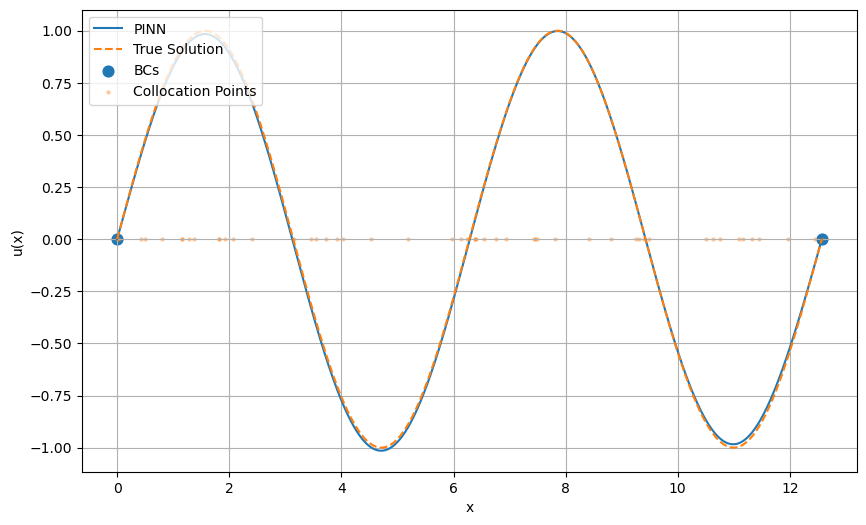


Average final L2 loss for each adaptivity: (N_dom = 50 )
 Non-adaptive: 1.76195e-02 with 2.70035e+01 (n=1)


In [8]:
# -------------------------------------------------------------------------------------
# -------------------------   Model run -----------------------------------------------
# -------------------------------------------------------------------------------------

layers = [1] + [50] * 4 + [1]
# N_dom = 30  # 50  # 20  # 50  # 30  # 20  # 10  # 20  # 50  # 100   # 20  # 200
N_dom_list = [50]  # [10, 20, 30, 40, 50]
max_epochs = (
    1000  # 3000  # 2000  # 10000  # 5500  # 8000 # 5000
    # 2000
    # 10000  # 8000  # 5000  # 3000  # 2000  # 10000  # 999    #14998 #25000 #2000 #25000
)
print_every = 500  # 200  # 200  # 200  # 500  # 2000  # 500  # 50  #5000 #500  #5000
move_every_value = 100  # print_every
# (
#     # 200  # 500  # 200  # 1000  # 200  # 1000  # 200  # 30  #3000 #250  #3000
# )
print_settings_flag = True
num_repeat_run = 1 #2  # 3  # 5
u = 1
nu = 1
w = 1  # 1  #      2  # 1  # 2  # 2  # 3  # 2  # 1


# ------------------ generate node and initial values for model -----------------------

# ---- PARAMETERS ----

seed = 140
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

tf.config.experimental.enable_op_determinism()  # force GPU to be deterministic for unique results for same setups


# device = "/GPU:0" if tf.config.list_physical_devices("GPU") else "/CPU:0"
device = "/CPU:0"

print(f"Using device: {device}")
x_min, x_max = 0.0, 4 * np.pi  # domain
lr = 1e-3

# ---- RUN TRAINING ----
CASE_TYPE = "advection_diffusion_1D"

rows = []
# rows_2 = []

for N_dom in N_dom_list:

    # 1. Generate your data globally or in main execution block

    x_interior = np.random.uniform(x_min, x_max, (N_dom, 1)).astype(np.float32)
    x_dom = np.concatenate([[[x_min]], x_interior, [[x_max]]], axis=0).astype(
        np.float32
    )

    x_b, u_b = gen_bc_tf([x_min, x_max], [np.sin(x_min), np.sin(x_max)])
    # x_b, u_b = gen_bc_tf([x_min], [np.sin(x_min)])

    x_dom_t = tf.Variable(x_dom, trainable=False, dtype=tf.float32)
    # x_bc_t = tf.constant(x_b, dtype=tf.float32)
    # phi_bc_t = tf.constant(u_b, dtype=tf.float32)
    x_bc_t = tf.Variable(x_b, dtype=tf.float32)
    phi_bc_t = tf.Variable(u_b, dtype=tf.float32)

    # # Plot node coordinates (x_dom_t)
    # if hasattr(x_dom, "numpy"):
    #     x_dom = x_dom.numpy()
    # x_dom = np.array(x_dom).flatten()

    # plt.figure(figsize=(12,8))
    # plt.scatter(x_dom, np.zeros_like(x_dom), color="b", marker="d")  # plot x locations
    # plt.title('Collocation nodes (x_dom)')
    # plt.xlabel("x-coordinate")
    # plt.ylabel("y")  # y=0 just for visualization
    # plt.grid(True)
    # plt.show()

    # 2. Define the RHS source term
    f_rhs_fun = f_rhs_fun_1d_sin

    # def f_rhs_fun(x_dom_t, w, u, nu):
    #     return u * w * tf.cos(w * x_dom_t) - nu * (w**2) * tf.sin(w * x_dom_t)

    f_rhs = f_rhs_fun(x_dom, w, u, nu)

    f_rhs_t = tf.convert_to_tensor(f_rhs, dtype=tf.float32)
    # f_rhs_t = tf.constant(f_rhs, dtype=tf.float32)

    # 3. Create a configuration dictionary for the PDE parameters
    pde_config = {"u": 1.0, "nu": 1.0, "f_tensor": f_rhs_t}

    # 4. Create a configuration dictionary for the BC parameters
    bc_config = {"phi_bc_t": phi_bc_t}

    # ------------------ End generate node and initial values for model -----------------------

    for move_every in [move_every_value]:

        for i_repeat_run in range(num_repeat_run):

            print(
                f"=== Running case '{CASE_TYPE}' === N_dom: {N_dom}"
            )

            # Reset random seed for each run to ensure reproducibility and fair comparison
            random.seed(seed + i_repeat_run)
            np.random.seed(seed + i_repeat_run)
            tf.random.set_seed(seed + i_repeat_run)

            (
                model,
                test_list,
                training_list,
                pos_hist,
                ep_hist,
                pred_hist,
                train_time,
                x_val,
                u_pred,
                u_true,
                x_dom,
                error_val_record_hist,
            ) = train(
                pde_residual_1d_second_order,
                bc_residual_Dirichlet_1D_v2,
                exact_solution_second_order_1d_general,
                x_dom_t,
                x_bc_t,
                phi_bc_t,
                pde_config,
                bc_config,
                print_settings_flag,
            )
            # ------------------ End generate node and initial values for model -----------------------

            rows.append(
                {
                    "Case": CASE_TYPE,
                    "Method": "node_moving_BC",
                    "N_dom": N_dom,
                    "Adaptivity": "Non-adaptive",
                    # "Adaptivity": N_dom,
                    "move_frequency": move_every,
                    "Final Test L2": test_list[-1],
                    "test_list": test_list,
                    "training_list": training_list,
                    "pos_hist": pos_hist,
                    "ep_hist": ep_hist,
                    "pred_hist": pred_hist,
                    "Train Time (s)": train_time,
                    "x_val": x_val,
                    "u_pred": u_pred,
                    "u_true": u_true,
                    "error_val_record_hist": error_val_record_hist,
                }
            )

df = pd.DataFrame(rows)

print(
    "\nAverage final L2 loss for each adaptivity: (N_dom =",
    str(N_dom),
    ")",
)
for adapt, gdf in df.groupby("Adaptivity"):
    mean_l2 = gdf["Final Test L2"].mean()
    mean_time = gdf["Train Time (s)"].mean()
    print(f" {adapt}: {mean_l2:.5e} with {mean_time:.5e} (n={len(gdf)})")